# Lab 11: Government Data APIs

*INFO 4617/5617 · Week 11 · Chapter 11, [Government Data APIs](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-11-government.html)*

Today we code together. Each step below says what we're building and why, and its code cell holds only the comments that frame it: we write the code live, in class. Nothing here is turned in.

We'll answer one question with two public APIs: **how did Boulder's housing come to look the way it does?** The Census Bureau tells us what the housing stock is today; FRED, the Federal Reserve Bank of St. Louis's data service, tells us about the economy it was built in.

| Step | What we build | Minutes |
|---|---|---|
| 0 | Setup: keys from the environment, never in the notebook | 5 |
| 1 | Find a variable in the Census catalog | 8 |
| 2–4 | Query Boulder, compare it with Longmont, and sanity-check a number | 22 |
| 5–7 | FRED series, a transformation the server does for us, and Denver against the nation | 25 |
| 8 | Put the two together | 10 |
| 9 | Optional: campaign finance from the FEC | — |
| 10 | What did we learn? | 5 |

**Before class:** request free keys from the [Census Bureau](https://api.census.gov/data/key_signup.html) and [FRED](https://fred.stlouisfed.org/docs/api/api_key.html) (and, for Step 9, the [FEC](https://api.open.fec.gov/developers/)). Set them as the environment variables `CENSUS_API_KEY` and `FRED_API_KEY` before you start Jupyter; *Missing Manual* Chapter 34 shows how. Approval can take a few minutes, so don't wait until class.

> **Instructor key.** Every cell from Step 0 to Step 8 is filled in and was run against the live APIs on 2026-10-20. Census figures come from the 2018–2022 American Community Survey and won't change; FRED requests end on 2026-09-30, but FRED can revise past values. Step 9 is filled in but wasn't run, because this run had no FEC key.

## Step 0 — Set up, and keep the keys out of the notebook (5 minutes)

An API key identifies you, counts your requests, and is yours alone. A key typed into a notebook travels with the notebook: into a GitHub repository, a class submission, a classmate's laptop. Read the keys from environment variables instead, and stop with a clear message if one is missing.

In [1]:
# Import os, requests, pandas (as pd), and matplotlib.pyplot (as plt)
# Read CENSUS_API_KEY and FRED_API_KEY from the environment (os.environ.get)
# If either is missing, raise an error that says which one, and how to set it
import os
import requests
import pandas as pd
import matplotlib.pyplot as plt

census_key = os.environ.get("CENSUS_API_KEY")
fred_key = os.environ.get("FRED_API_KEY")
for name, key in [("CENSUS_API_KEY", census_key), ("FRED_API_KEY", fred_key)]:
    if not key:
        raise ValueError(f"{name} isn't set: set it in your terminal, then restart Jupyter")
print("Keys found")

Keys found


## Step 1 — Find a variable in the Census catalog (8 minutes)

The American Community Survey has thousands of variables, organized in groups. Group `B25034` is "Year Structure Built". Its catalog is itself an API: ask for the group's JSON and print each variable's code and label. Codes ending in `E` are estimates; those ending in `M` are margins of error, so skip them. Browse the other groups at [api.census.gov/data/2022/acs/acs5/groups.html](https://api.census.gov/data/2022/acs/acs5/groups.html).

In [2]:
# Request https://api.census.gov/data/2022/acs/acs5/groups/B25034.json
# For each variable, in order, print its code and label, skipping the margins of error
groups_url = "https://api.census.gov/data/2022/acs/acs5/groups/B25034.json"
response = requests.get(groups_url, timeout=30)
response.raise_for_status()
variables = response.json()["variables"]

for code, info in sorted(variables.items()):
    if code.endswith("E") and "label" in info:
        print(code, info["label"])

B25034_001E Estimate!!Total:
B25034_002E Estimate!!Total:!!Built 2020 or later
B25034_003E Estimate!!Total:!!Built 2010 to 2019
B25034_004E Estimate!!Total:!!Built 2000 to 2009
B25034_005E Estimate!!Total:!!Built 1990 to 1999
B25034_006E Estimate!!Total:!!Built 1980 to 1989
B25034_007E Estimate!!Total:!!Built 1970 to 1979
B25034_008E Estimate!!Total:!!Built 1960 to 1969
B25034_009E Estimate!!Total:!!Built 1950 to 1959
B25034_010E Estimate!!Total:!!Built 1940 to 1949
B25034_011E Estimate!!Total:!!Built 1939 or earlier
NAME Geographic Area Name


## Step 2 — Ask about one place (8 minutes)

Places are named by FIPS codes: Colorado is state `08`, and Boulder is place `07850`. Ask for the place's name and the first few `B25034` estimates. The Census answers with a list of lists whose first row is the header, and every value is a string: make a DataFrame, and turn the numbers into numbers.

In [3]:
# census_url = "https://api.census.gov/data/2022/acs/acs5"
# params: get="NAME,B25034_001E,...,B25034_005E", for="place:07850", in="state:08", key=census_key
# Make a DataFrame from rows 1 onward, with row 0 as the columns, and convert the B25034 columns to numbers
census_url = "https://api.census.gov/data/2022/acs/acs5"
columns = ["B25034_001E", "B25034_002E", "B25034_003E", "B25034_004E", "B25034_005E"]
params = {"get": "NAME," + ",".join(columns), "for": "place:07850", "in": "state:08",
          "key": census_key}
response = requests.get(census_url, params=params, timeout=30)
response.raise_for_status()
rows = response.json()

housing = pd.DataFrame(rows[1:], columns=rows[0])
housing[columns] = housing[columns].apply(pd.to_numeric)
housing

,NAME,B25034_001E,B25034_002E,B25034_003E,B25034_004E,B25034_005E,state,place
0,"Boulder city, Colorado",46551,68,3784,3847,5931,08,07850


## Step 3 — Compare two places (7 minutes)

Several places can go in one request: `place:07850,45970` is Boulder and Longmont. Plot the two cities' housing by decade built, side by side.

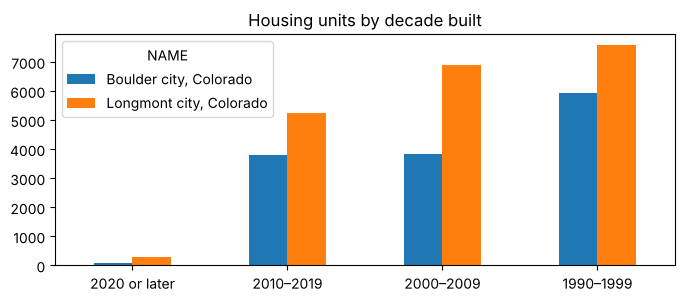

In [4]:
# Ask again with for="place:07850,45970"
# Plot the decades (002E through 005E) as grouped bars, one color per city
params["for"] = "place:07850,45970"
response = requests.get(census_url, params=params, timeout=30)
response.raise_for_status()
rows = response.json()
compare = pd.DataFrame(rows[1:], columns=rows[0])
compare[columns] = compare[columns].apply(pd.to_numeric)

decades = compare.set_index("NAME")[columns[1:]].T
decades.index = ["2020 or later", "2010–2019", "2000–2009", "1990–1999"]
decades.plot(kind="bar", figsize=(8, 3), rot=0, title="Housing units by decade built")
plt.show()

## Step 4 — Sanity-check a number (7 minutes)

A variable with the right-sounding label can still be the wrong one. Before trusting a pipeline, check one value you can judge. Ask for Boulder's median household income (`B19013_001E`). Does it look like a city's median income: tens of thousands of dollars, not 7 or 70 million?

In [5]:
# Ask for NAME and B19013_001E for Boulder (place:07850 in state:08)
# Print the city and its median household income, formatted with a dollar sign and commas
params = {"get": "NAME,B19013_001E", "for": "place:07850", "in": "state:08", "key": census_key}
response = requests.get(census_url, params=params, timeout=30)
response.raise_for_status()
name, income = response.json()[1][:2]
print(f"{name}: ${int(income):,}")

Boulder city, Colorado: $80,243


## Step 5 — A FRED series (8 minutes)

FRED holds hundreds of thousands of time series, each with an ID you find by searching [fred.stlouisfed.org](https://fred.stlouisfed.org/). `MHICO08013A052NCEN` is median household income for Boulder County, from the Census Bureau's SAIPE program; the ID embeds the state (`CO`) and the county's FIPS code (`08013`). Ask for its observations. FRED writes a missing value as `"."`, so convert with `errors="coerce"`.

In [6]:
# fred_url = "https://api.stlouisfed.org/fred/series/observations"
# params: series_id, api_key=fred_key, file_type=json, observation_end="2026-09-30"
# Make a DataFrame from ["observations"]; convert date to dates and value to numbers; show the last rows
fred_url = "https://api.stlouisfed.org/fred/series/observations"

def fred_series(series_id, **extra):
    params = {"series_id": series_id, "api_key": fred_key, "file_type": "json",
              "observation_end": "2026-09-30", **extra}
    response = requests.get(fred_url, params=params, timeout=30)
    response.raise_for_status()
    series = pd.DataFrame(response.json()["observations"])
    series["date"] = pd.to_datetime(series["date"])
    series["value"] = pd.to_numeric(series["value"], errors="coerce")
    return series[["date", "value"]]

income = fred_series("MHICO08013A052NCEN")
income.tail()

,date,value
31,2020-01-01,88289.0
32,2021-01-01,90327.0
33,2022-01-01,96584.0
34,2023-01-01,97170.0
35,2024-01-01,103293.0


## Step 6 — Let the server do the math (7 minutes)

FRED can transform a series before it sends it. `units="pc1"` returns the percent change from a year before, so the Consumer Price Index (`CPIAUCSL`) comes back as the inflation rate. Plot it since 2020, with a line at the Federal Reserve's 2% target.

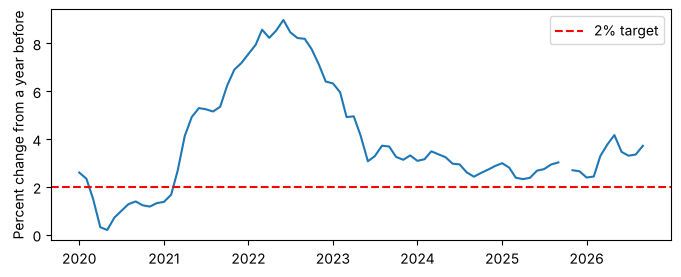

In [7]:
# Ask for CPIAUCSL with units="pc1" and observation_start="2020-01-01"
# Plot it, with a dashed horizontal line at 2
inflation = fred_series("CPIAUCSL", units="pc1", observation_start="2020-01-01")

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(inflation["date"], inflation["value"])
ax.axhline(2, color="red", linestyle="--", label="2% target")
ax.set_ylabel("Percent change from a year before")
ax.legend()
plt.show()

## Step 7 — Denver against the nation (10 minutes)

National numbers hide local ones. `CUUSA433SA0` is the CPI for the Denver area. The Bureau of Labor Statistics publishes it once a year, and it isn't seasonally adjusted, so compare it with the national series that isn't either, `CPIAUCNS`, which FRED can average into years for you (`frequency="a"`). Ask for both as year-over-year changes since 2000, merge them on date, and plot them together. The merge keeps only the years both series have.

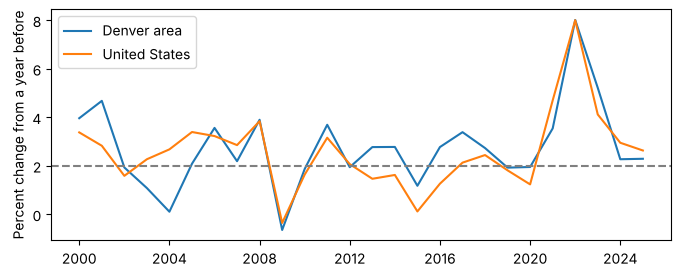

In [8]:
# Ask for CUUSA433SA0, and CPIAUCNS with frequency="a"; both with units="pc1" and observation_start="2000-01-01"
# Merge them on date (inner), and plot both lines with a dashed line at 2
denver = fred_series("CUUSA433SA0", units="pc1", observation_start="2000-01-01")
national = fred_series("CPIAUCNS", frequency="a", units="pc1", observation_start="2000-01-01")
both = denver.merge(national, on="date", suffixes=("_denver", "_national"))

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(both["date"], both["value_denver"], label="Denver area")
ax.plot(both["date"], both["value_national"], label="United States")
ax.axhline(2, color="gray", linestyle="--")
ax.set_ylabel("Percent change from a year before")
ax.legend()
plt.show()

## Step 8 — Put the two together (10 minutes)

The Census says what Boulder's housing is; FRED says what borrowing cost when it was built. Ask the Census for Boulder's housing by decade back to the 1970s (`B25034_002E` to `B25034_007E`), and FRED for the 30-year mortgage rate as yearly averages (`MORTGAGE30US`, `frequency="a"`) since 1970. Plot them side by side.

One trap: the Census marks a value it can't publish with a code such as `-666666666`, not a blank. Check for it before you convert.

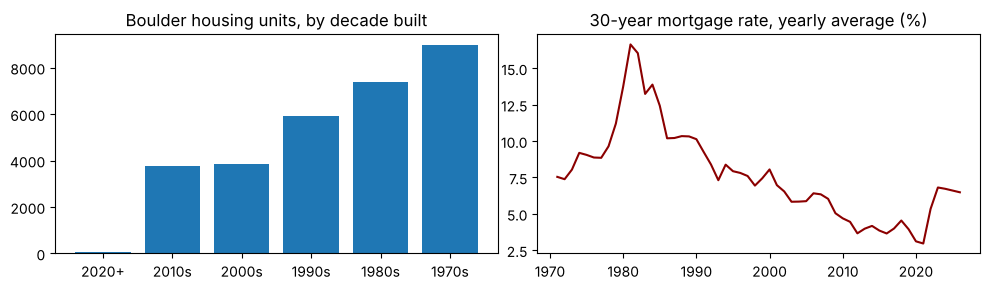

In [9]:
# Census: NAME and B25034_002E through B25034_007E for Boulder; turn codes starting with -6666 into missing values
# FRED: MORTGAGE30US with frequency="a" and observation_start="1970-01-01"
# Two panels: bars of housing by decade, and the mortgage rate over time
vintage = [f"B25034_{n:03d}E" for n in range(2, 8)]
params = {"get": "NAME," + ",".join(vintage), "for": "place:07850", "in": "state:08",
          "key": census_key}
response = requests.get(census_url, params=params, timeout=30)
response.raise_for_status()
values = response.json()[1][1:7]
counts = [None if v is None or str(v).startswith("-6666") else int(v) for v in values]

mortgage = fred_series("MORTGAGE30US", frequency="a", observation_start="1970-01-01")

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3))
left.bar(["2020+", "2010s", "2000s", "1990s", "1980s", "1970s"], counts)
left.set_title("Boulder housing units, by decade built")
right.plot(mortgage["date"], mortgage["value"], color="darkred")
right.set_title("30-year mortgage rate, yearly average (%)")
plt.tight_layout()
plt.show()

## Step 9 — Optional: campaign finance from the FEC (if there's time)

The Federal Election Commission's API needs a third key, `FEC_API_KEY`. Search for candidates by name, then ask for one candidate's totals: IDs start with the office sought (`P` for president, `S` for Senate, `H` for House).

In [ ]:
# Read FEC_API_KEY from the environment
# Search https://api.open.fec.gov/v1/candidates/search/ for q="Biden", office="P", election_year=2024
# Then get totals from https://api.open.fec.gov/v1/candidate/P80000722/totals/ for 2024
fec_key = os.environ["FEC_API_KEY"]
search = requests.get("https://api.open.fec.gov/v1/candidates/search/",
                      params={"q": "Biden", "office": "P", "election_year": 2024,
                              "api_key": fec_key, "per_page": 5}, timeout=30)
search.raise_for_status()
for candidate in search.json()["results"]:
    print(candidate["name"], candidate["candidate_id"], candidate["party_full"])

totals = requests.get("https://api.open.fec.gov/v1/candidate/P80000722/totals/",
                      params={"election_year": 2024, "api_key": fec_key}, timeout=30)
totals.raise_for_status()
for row in totals.json()["results"]:
    print(row["cycle"], f"receipts ${row['receipts']:,.0f}")

## Step 10 — What did we learn? (5 minutes)

In a few sentences, as comments or in a Markdown cell:

- Which decade built the most of Boulder's housing, and which the least? Does the mortgage rate explain it, or does something else, such as the city's limits on growth?
- When did Denver's inflation run above the nation's, and by how much at most?
- Where did each API make you look something up: a variable code, a series ID, a FIPS code? Where would you look next time?

In [10]:
# Your answers here, as comments
# Of the decades we asked for, the 1970s built the most of Boulder's housing (8,980 units)
# and each decade since has built less: 7,400 in the 1980s, 3,784 in the 2010s. "2020 or later"
# (68) is the smallest, but it covers only 2020-2022, the survey's last years.
# Mortgage rates don't explain it: they peaked near 17% in 1981 and fell to 3% by 2021, while
# building kept slowing. The city's limits on growth (the 1976 Danish Plan, the blue line,
# open space purchases) fit the pattern better than the price of borrowing.
#
# Denver's inflation ran above the nation's most years from 2013 to 2020, by up to 1.5 points
# (2016), and again in 2023 (1.1 points). The largest gap either way was 2004, when Denver
# ran 2.6 points below.
#
# Lookups: the Census variable codes came from the group catalog (Step 1); the place codes
# (07850 Boulder, 45970 Longmont) and state 08 are FIPS codes; the FRED IDs came from
# searching fred.stlouisfed.org.